# Análisis Factorial: indicadores estatales de la ENIGH 2024

Cuaderno del **Capítulo 3** de las notas. Construye seis indicadores por entidad federativa a partir del microdato de la ENIGH 2024 (tabla `concentradohogar`, INEGI) y estima un modelo factorial con el módulo `utils/factorial.py`, escrito con `numpy` y `scipy` para que cada paso coincida con las fórmulas de las notas.

**Contenido**
1. Construcción de la base de datos (32 entidades × 6 indicadores)
2. Adecuación: Bartlett, KMO y MSA
3. Un factor y tres variables: solución cerrada
4. Estimación: componentes principales, ejes principales y máxima verosimilitud
5. Rotación: varimax y promax
6. Puntuaciones factoriales (regresión y Bartlett)
7. Confiabilidad: alfa de Cronbach y omega de McDonald

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
np.set_printoptions(suppress=True, precision=3)
pd.set_option("display.precision", 3)
AZUL, NARANJA, VERDE, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#d9d8d4", "figure.dpi": 110})
import sys, zipfile
sys.path.insert(0, "../../utils")
import factorial as fa

## 1. Construcción de la base de datos

Cada hogar se pondera con su factor de expansión (`factor`). Las proporciones son cocientes de totales ponderados.

In [2]:
ENTIDADES = ["Aguascalientes", "Baja California", "Baja California Sur", "Campeche", "Coahuila",
             "Colima", "Chiapas", "Chihuahua", "Ciudad de México", "Durango", "Guanajuato",
             "Guerrero", "Hidalgo", "Jalisco", "México", "Michoacán", "Morelos", "Nayarit",
             "Nuevo León", "Oaxaca", "Puebla", "Querétaro", "Quintana Roo", "San Luis Potosí",
             "Sinaloa", "Sonora", "Tabasco", "Tamaulipas", "Tlaxcala", "Veracruz", "Yucatán",
             "Zacatecas"]
with zipfile.ZipFile("../03 ENIGH/enigh2024_ns_concentradohogar_csv.zip") as z:
    hog = pd.read_csv(z.open("concentradohogar.csv"), low_memory=False, dtype={"ubica_geo": str})
g = hog.ubica_geo.str.zfill(5).str[:2].astype(int)
w = hog.factor
media = lambda x: (x * w).groupby(g).sum() / w.groupby(g).sum()
cociente = lambda num, den: (num * w).groupby(g).sum() / (den * w).groupby(g).sum()

X = pd.DataFrame({
    "ing_pc": np.log(media(hog.ing_cor / hog.tot_integ)),   # log ingreso corriente trimestral pc
    "edu_jefe": media(hog.educa_jefe),                       # escala 1-11 de la ENIGH
    "menores_sh": cociente(hog.menores, hog.tot_integ),      # menores de 12 años
    "perceptores": cociente(hog.percep_ing, hog.tot_integ),
    "mayores65_sh": cociente(hog.p65mas, hog.tot_integ),
    "trab_sh": cociente(hog.ingtrab, hog.ing_cor),
})
X.index = ENTIDADES
X.index.name = "entidad"
X = X.round(4)          # se trabaja con los valores que se guardan, para coincidir con las notas
X.to_csv("enigh2024_entidades.csv")
print(hog.shape[0], "hogares")
X.round(3)

91414 hogares


,ing_pc,edu_jefe,menores_sh,perceptores,mayores65_sh,trab_sh
entidad,,,,,,
Aguascalientes,10.364,6.702,0.193,0.648,0.088,0.656
Baja California,10.551,6.599,0.166,0.623,0.089,0.707
Baja California Sur,10.607,6.844,0.172,0.681,0.066,0.694
Campeche,10.037,6.080,0.181,0.637,0.090,0.644
Coahuila,10.346,6.722,0.184,0.622,0.089,0.707
Colima,10.462,6.536,0.158,0.725,0.104,0.644
Chiapas,9.500,5.082,0.221,0.585,0.084,0.669
Chihuahua,10.440,6.458,0.176,0.651,0.091,0.673
Ciudad de México,10.781,7.434,0.107,0.796,0.144,0.610


In [3]:
R = X.corr().values
n, p = X.shape
pd.DataFrame(R, index=X.columns, columns=X.columns).round(3)

,ing_pc,edu_jefe,menores_sh,perceptores,mayores65_sh,trab_sh
ing_pc,1.000,0.909,-0.668,0.545,-0.164,0.170
edu_jefe,0.909,1.000,-0.669,0.499,-0.201,0.274
menores_sh,-0.668,-0.669,1.000,-0.711,-0.351,0.137
perceptores,0.545,0.499,-0.711,1.000,0.363,-0.362
mayores65_sh,-0.164,-0.201,-0.351,0.363,1.000,-0.773
trab_sh,0.170,0.274,0.137,-0.362,-0.773,1.000


## 2. Adecuación de los datos

In [4]:
chi2, gl, pval = fa.bartlett_esfericidad(R, n)
print(f"Bartlett: |R| = {np.linalg.det(R):.4f}, χ² = {chi2:.1f}, gl = {gl:.0f}, p = {pval:.1e}")
kmo, msa = fa.kmo(R)
print(f"KMO = {kmo:.3f}")
print(pd.Series(msa, index=X.columns, name="MSA").round(3))
print("Correlaciones parciales:\n", pd.DataFrame(fa.correlaciones_parciales(R), index=X.columns, columns=X.columns).round(3))

Bartlett: |R| = 0.0064, χ² = 142.2, gl = 15, p = 8.4e-23
KMO = 0.657
ing_pc          0.689
edu_jefe        0.705
menores_sh      0.694
perceptores     0.807
mayores65_sh    0.509
trab_sh         0.510
Name: MSA, dtype: float64
Correlaciones parciales:
               ing_pc  edu_jefe  menores_sh  perceptores  mayores65_sh  trab_sh
ing_pc         1.000     0.749      -0.194        0.110        -0.270   -0.222
edu_jefe       0.749     1.000      -0.253        0.063        -0.057    0.232
menores_sh    -0.194    -0.253       1.000       -0.393        -0.573   -0.309
perceptores    0.110     0.063      -0.393        1.000        -0.068   -0.372
mayores65_sh  -0.270    -0.057      -0.573       -0.068         1.000   -0.692
trab_sh       -0.222     0.232      -0.309       -0.372        -0.692    1.000


## 3. Un factor y tres variables: solución cerrada

$\ell_1^2 = r_{12}r_{13}/r_{23}$, $\ell_2^2 = r_{12}r_{23}/r_{13}$, $\ell_3^2 = r_{13}r_{23}/r_{12}$.

In [5]:
r12, r13, r23 = R[0, 1], R[0, 2], R[1, 2]          # ingreso, escolaridad, menores
l2 = np.array([r12 * r13 / r23, r12 * r23 / r13, r13 * r23 / r12])
ell = np.sqrt(l2) * np.array([1, 1, -1])
print("Cargas:", ell.round(3), "| unicidades:", (1 - l2).round(3))
print("ℓℓ' reproduce las correlaciones:\n", np.outer(ell, ell).round(3))

Cargas: [ 0.953  0.954 -0.701] | unicidades: [0.092 0.089 0.508]
ℓℓ' reproduce las correlaciones:
 [[ 0.908  0.909 -0.668]
 [ 0.909  0.911 -0.669]
 [-0.668 -0.669  0.492]]


## 4. Estimación con tres métodos

In [6]:
lam = np.linalg.eigvalsh(R)[::-1]
print("Eigenvalores:", lam.round(3), "| acumulada:", (lam.cumsum() / p).round(3))
Lpc = fa.fa_componentes(R, 2); Lpc *= np.sign(Lpc[0])
Lpa, it = fa.fa_ejes_principales(R, 2); Lpa *= np.sign(Lpa[0])
L, psi, F = fa.fa_maxima_verosimilitud(R, 2); L *= np.sign(L[0])
tabla = pd.DataFrame(np.c_[Lpc, (Lpc**2).sum(1), Lpa, (Lpa**2).sum(1), L, 1 - psi], index=X.columns,
                     columns=pd.MultiIndex.from_product([["Componentes", "Ejes principales", "Máx. verosimilitud"],
                                                         ["l1", "l2", "h2"]]))
print("Ejes principales: iteraciones =", it)
tabla.round(3)

Eigenvalores: [3.025 2.123 0.359 0.296 0.118 0.08 ] | acumulada: [0.504 0.858 0.918 0.967 0.987 1.   ]
Ejes principales: iteraciones = 67


Componentes               Ejes principales                \
                      l1     l2     h2               l1     l2     h2   
ing_pc             0.882  0.344  0.896            0.883  0.290  0.864   
edu_jefe           0.864  0.416  0.920            0.887  0.372  0.926   
menores_sh        -0.897  0.165  0.833           -0.846  0.206  0.758   
perceptores        0.811 -0.345  0.777            0.728 -0.346  0.650   
mayores65_sh       0.175 -0.919  0.875            0.136 -0.911  0.848   
trab_sh           -0.081  0.917  0.848           -0.043  0.832  0.694   

             Máx. verosimilitud                
                             l1     l2     h2  
ing_pc                    0.942  0.033  0.888  
edu_jefe                  0.963 -0.020  0.929  
menores_sh               -0.705 -0.513  0.760  
perceptores               0.547  0.546  0.597  
mayores65_sh             -0.196  0.923  0.891  
trab_sh                   0.252 -0.776  0.666

In [7]:
for m in [1, 2]:
    Lm, psim, Fm = fa.fa_maxima_verosimilitud(R, m)
    est, glm, pm = fa.prueba_ajuste_mv(Fm, n, p, m)
    print(f"m = {m}: χ² = {est:.2f}, gl = {glm:.0f}, p = {pm:.3g}")
res = R - L @ L.T - np.diag(psi)
print("Máximo residuo |r - σ̂| con m = 2:", np.abs(res).max().round(3))

m = 1: χ² = 61.44, gl = 9, p = 7.06e-10
m = 2: χ² = 8.68, gl = 4, p = 0.0696
Máximo residuo |r - σ̂| con m = 2: 0.083


## 5. Rotación

In [8]:
Lv, T = fa.varimax(L)
print("Matriz de rotación T:\n", T.round(3), "| ángulo =", np.degrees(np.arctan2(T[1, 0], T[0, 0])).round(1), "grados")
print(pd.DataFrame(np.c_[Lv, (Lv**2).sum(1)], index=X.columns, columns=["F1", "F2", "h2"]).round(3))
print("Criterio varimax: sin rotar", fa.varimax_criterio(L).round(3), "| rotada", fa.varimax_criterio(Lv).round(3))
patron, Phi = fa.promax(L)
print("Promax, correlación entre factores:", Phi[0, 1].round(3))

Matriz de rotación T:
 [[ 0.966 -0.257]
 [ 0.257  0.966]] | ángulo = 14.9 grados
                 F1     F2     h2
ing_pc        0.919 -0.210  0.888
edu_jefe      0.926 -0.268  0.929
menores_sh   -0.813 -0.314  0.760
perceptores   0.669  0.386  0.597
mayores65_sh  0.048  0.943  0.891
trab_sh       0.044 -0.815  0.666
Criterio varimax: sin rotar 0.293 | rotada 0.345
Promax, correlación entre factores: 0.155


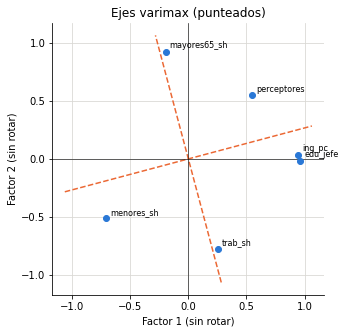

In [9]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(L[:, 0], L[:, 1], color=AZUL, zorder=3)
for j, v in enumerate(X.columns):
    ax.annotate(v, (L[j, 0], L[j, 1]), xytext=(4, 4), textcoords="offset points", fontsize=8)
for c in range(2):
    ax.plot([-1.1 * T[0, c], 1.1 * T[0, c]], [-1.1 * T[1, c], 1.1 * T[1, c]], color=NARANJA, ls="--")
ax.axhline(0, color=TINTA, lw=0.6); ax.axvline(0, color=TINTA, lw=0.6)
ax.set_aspect("equal"); ax.set_xlabel("Factor 1 (sin rotar)"); ax.set_ylabel("Factor 2 (sin rotar)")
ax.set_title("Ejes varimax (punteados)"); plt.show()

## 6. Puntuaciones factoriales

In [10]:
Z = ((X - X.mean()) / X.std(ddof=0)).values
Freg = pd.DataFrame(fa.puntuaciones_regresion(Z, R, Lv), index=X.index, columns=["F1", "F2"])
Fbar = pd.DataFrame(fa.puntuaciones_bartlett(Z, Lv, psi), index=X.index, columns=["F1", "F2"])
print("Varianza (regresión):", Freg.var(ddof=0).round(3).tolist(), "= diag(L'R⁻¹L):", np.diag(Lv.T @ np.linalg.solve(R, Lv)).round(3).tolist())
print("Varianza (Bartlett):", Fbar.var(ddof=0).round(3).tolist())
print("Correlación regresión-Bartlett:", [round(np.corrcoef(Freg.iloc[:, j], Fbar.iloc[:, j])[0, 1], 4) for j in range(2)])
Freg.to_csv("enigh2024_puntuaciones.csv")
Freg.sort_values("F1").round(3)

Varianza (regresión): [0.958, 0.923] = diag(L'R⁻¹L): [0.958, 0.923]
Varianza (Bartlett): [1.044, 1.084]
Correlación regresión-Bartlett: [0.9999, 0.9999]


,F1,F2
entidad,,
Chiapas,-2.480,-0.717
Guerrero,-1.731,0.563
Oaxaca,-1.669,1.025
Michoacán,-0.835,0.108
Puebla,-0.802,0.278
Veracruz,-0.788,1.700
Zacatecas,-0.767,0.454
Tlaxcala,-0.546,-0.183
Guanajuato,-0.506,0.185


## 7. Confiabilidad de la escala socioeconómica

In [11]:
Zs = Z[:, :4] * np.array([1, 1, -1, 1])           # menores con polaridad invertida
print("Alfa de Cronbach (estandarizado):", fa.alfa_cronbach(Zs).round(3))
L1, psi1, _ = fa.fa_maxima_verosimilitud(np.corrcoef(Zs.T), 1)
L1 = np.abs(L1.ravel())
print("Cargas de un factor:", L1.round(3), "| omega =", (L1.sum()**2 / (L1.sum()**2 + psi1.sum())).round(3))

Alfa de Cronbach (estandarizado): 0.889
Cargas de un factor: [0.96  0.944 0.715 0.574] | omega = 0.883


## Ejercicios para el alumno

1. Repita el análisis sin la Ciudad de México. ¿Cambian el número de factores, las cargas y la prueba de ajuste?
2. Calcule a mano la puntuación de Bartlett de la Ciudad de México y compárela con la tabla.
3. Estime el modelo con los seis indicadores a nivel **hogar** y compare las cargas con las del análisis estatal (falacia ecológica).